# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 3.1 Базовая генерация признаков

### Общая информация

Дата выдачи: 31.10.2026

Мягкий дедлайн: 13.11.2026 23:59MSK

Жесткий дедлайн: 18.11.2026 23:59MSK

### О задании

В данном задании вы познакомитесь с базовыми подходами для создания новых признаков в табличном машинном обучении. Вам понадобится подумать над тем, зачем мы делаем те или иные преобразования, научиться принимать решения, дающие наилучшие результаты, и узнать, как реализовывать их при помощи библиотек

### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за эту часть — 6 баллов. Детальнее про оценивание — в самом конце ноутбука.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате **homework-practice-03-base-Username.ipynb**, где Username — ваша фамилия.

### **Сетап**

<img style="float: right; padding-right:15px; padding-bottom:10px" src="https://i.postimg.cc/26KqqSb2/pomoika2.png" height=300px width=200px alt="Pomoika 2">
    
В этом домашнем задании мы будем работать с задачей классификации, но сконцентрируемся на том, что приносит не меньшую пользу, чем сами модели — замешиванию данных.

Целевая метрика уже выбрана за нас: мы будем считать $\text{ROC-AUC}$, но не простой, а коэффициент Джини:

$$ \text{Gini} = 2 \cdot \text{ROC-AUC} - 1$$

Конечная цель данного мероприятия — собрать пайплайн машинного обучения от и до, начиная с предобработки данных, заканчивая оптимизацией. При желании это можно доделать до целого пет-проекта, особенно если добавить сбор данных и деплой модели, но в дз этого не будет :(.

Цель конкретно базового ноутбука — познакомить вас с основными преобразованиями и собрать солидный фундамент для преобразований посложнее. 

In [1]:
from math import remainder

import category_encoders
import sklearn
from narwhals.exceptions import ColumnNotFoundError
from pandas.core.reshape import merge
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sympy import true


def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1.0

#### **Данные**

У вас на руках (на Kaggle) датасет по широко известной в неузких кругах видеоигре Dota 2, скачанный через OpenDota API и заботливо анонимизированный. Если вы не знакомы с игрой — ничего страшного, все необходимое для заданий в базовой части мы подробно опишем.

Нас интересует исход матча — победа или поражение, исходя из совершенно разных факторов (например, чтобы делать ставки на спорт, осуждаем?). Это информация о сессии, игроках, героях, и т д. **в первые 15 минут** после начала матча.

Краткая сводка об игре:

- Dota 2 — командная игра: 5 игроков за Свет (Radiant) против 5 за Тьму (Dire).
- Каждый игрок управляет уникальным героем со своим набором атрибутов и способностей.
- Цель — снести главную постройку на вражеской базе (в простонародье трон).
- В процессе матча игроки добывают золото и опыт, покупают предметы и убивают противников, чтобы стать сильнее.
- Ничьих не бывает, фиксированного таймера нет — матч длится до падения трона.

#### 📌 **Важнейшее замечание**

Предполагается, что у вас уже сложилось понимание:
- как крутить и вертеть данные, чтобы фиты делались твёрдо, трансформы ложились чётко, шейпы датафреймов стакались и нужные джойны джойнились;
- как рисовать читаемые графики;
- как проверять качество модели;

Пожалуйста, следите за этим очень-очень внимательно, иначе рискуете получить штраф и всеобщее порицание в нашем уютном МО-1 чатике (хотя, у этого есть плюсы).

Если возникнут вопросы по игровой части — **не стесняйтесь** спрашивать, гуглить, обращаться к GPT или, прости Господи, дотерам. Знание области — важнейшая составляющая хорошего фича инжиниринга

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Для лучшего понимания, в голубеньких пунктах будет небольшое <font color="#647cb8">**обоснование**</font> того, зачем вообще делается то или иное преобразование (в колабе придётся включать интуицию, там не работает HTML). Вы можете её скипнуть, если всё понятно и без этого

</div>

<div style="border-left: 5px solid #f68c9d; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

В пунктах с розоватой, как у всеми любимого Pudge, расцветкой мы попросим вас написать <font color="#f68c9d">**Ответ**</font> на <font color="#f68c9d">**Вопрос**</font> или <font color="#f68c9d">**рефлексию**</font>, которая должна направить вашу мысль о том, как варить фичи, в нужном направлении. Уметь аргументировать свою точку зрения важно не менее

Пожалуйста, даже если вы уже прожжённый дед инсайд и дата-сайентист 14 уо, всё равно <font color="#f68c9d">**порефлексируйте**</font>. Количество потерянных нервных клеток и ваш успех на соревновании напрямую зависят от базовой предобработки.
Вы **можете** писать <font color="#f68c9d">**её**</font> ёмко, но только если **знаете** ответ

</div>

<div style="border-left: 5px solid #cb9255; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(200, 156, 105, 0.05);">

<font>По ходу домашки вам придётся делать <font color="#cb9255">**выборы**</font> и подбирать <font color="#cb9255">**гиперпараметры**</font>. Какие-то из них важнее остальных. У ряда выборов последствия чисто номинальные, какие-то видоизменят другие задания, третьи полностью определят, как вы будете делать остальную домашку. 

Принимайте решения мудро. Не привязывайтесь к ним слишком сильно, возможно, в процессе вам захочется пересмотреть ваши жизненные приоритеты. Пробуйте, экспериментируйте, фичи это самое творческое, что есть в машинном обучении

При желании, в конце обоих ноутбуков есть инструменты, которые, при остром желании и избытке свободного времени, могут тупо перебрать все выборы и найти самый оптимальный, но это опционально
</div>

### **Часть 1. Это, так сказать, база. (3.25 балла)** <img align="center" height=28 width=28 src="https://media.tenor.com/5vGX5VO-IxsAAAAi/arthas.gif">

В которой студент учится смотреть на фичи под правильным углом и готовить из сырых данных простые, но аппетитные факторы

#### **Задание 1.1. Датасет** (0.5 балла)

Чтобы начать работу с данными, эти данные сперва нужно [загрузить](https://www.kaggle.com/t/6fd940fbeb1746a78031e5d0277f6105). Пока что нам потребуются лишь:

1. Информация о матчах - `matches_df_train.csv`.
2. Тестовые данные для соревнования - `matches_df_test.csv`.

Посмотрите на все csv-файлы выше, создайте под каждый из них отдельный датафрейм и отметьте (текстом или кодом):
- объемы таблиц: как в Мб, так и `df.shape`
- какие в них есть колонки по своему содержанию

In [2]:
import pandas as pd

matches_train = pd.read_csv('matches_df_train.csv')
matches_test = pd.read_csv('matches_df_test.csv')
heroes = pd.read_csv('Constants.Heroes.csv')
dota_adv = pd.read_csv('dota_adv.csv')
players = pd.read_csv('player_df.csv')

In [3]:
matches_train.shape, matches_test.shape

((641090, 7), (59748, 5))

In [4]:
matches_train.head(3)

,match_id,date,region,game_mode,duration,radiant_win,avg_mmr
0,1,2024-02-12,Europe West,4,2625,False,3519.7
1,2,2024-04-08,South Africa,2,7526,True,2330.9
2,3,2024-06-16,SE Asia,1,2831,True,1579.6


In [5]:
matches_test.head(3)

,match_id,date,region,game_mode,avg_mmr
0,8,2024-12-01,China,1,2305.0
1,29,2024-12-17,Europe West,22,NaN
2,34,2024-12-19,Europe West,22,2278.5


In [6]:
matches_train.memory_usage(index=True, deep=True).sum() / 1024**2

np.float64(92.50748825073242)

Отдельно хочется посмотреть распределение целевой переменной, покажите его, пожалуйста

In [7]:
matches_train.groupby(['radiant_win'])['radiant_win'].count()

radiant_win
False    313639
True     327451
Name: radiant_win, dtype: int64

<div style="border-left: 5px solid #c27985; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** подходящая ли в данном случае метрика $	ext{Gini}$ в сравнении, например, с $	ext{AUC-PR}$?

**Ответ:** Да, Gini подходит, потому что классы примерно сбалансированы. Если бы положительный класс был редким, я бы также посмотрел на PR AUC.
</div>

#### **Задание 1.2. Категории** (0.75 балла)

Чтобы построить реально балдёжную модель, зачастую не получится просто написать фит предикт. О нет, это долгая и утомительная возня. А если нужно ещё и отчётики писать, то хоть <span style="color:grey"><font size="1">~~вешайся (осуждаем)~~ </font></span> увольняйся. Так и здесь. И того, что есть, уже хватит, чтобы продемонстрировать глубокую и тёмную сторону Dota Science.

В целом, данные уже содержат признаки, по которым что-то даже можно построить, в частности — регионы.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

У Radiant, по сравнению с Dire, исторически есть небольшое преимущество — чуть удобнее карта, порядок выбора героев и всё такое. В разных регионах бывают разные предпочтения по стилям игры и тактикам, и где-то это преимущество реализуют лучше

</div>

Посмотрите, где у нас содержится информация о регионе, на серверах которого был проведён матч, и постройте 2 графика:
1) Распределение регионов (процентное и абсолютное) на тренировочных и тестовых данных
2) Среднее значение таргета на трейне, в зависимости от региона

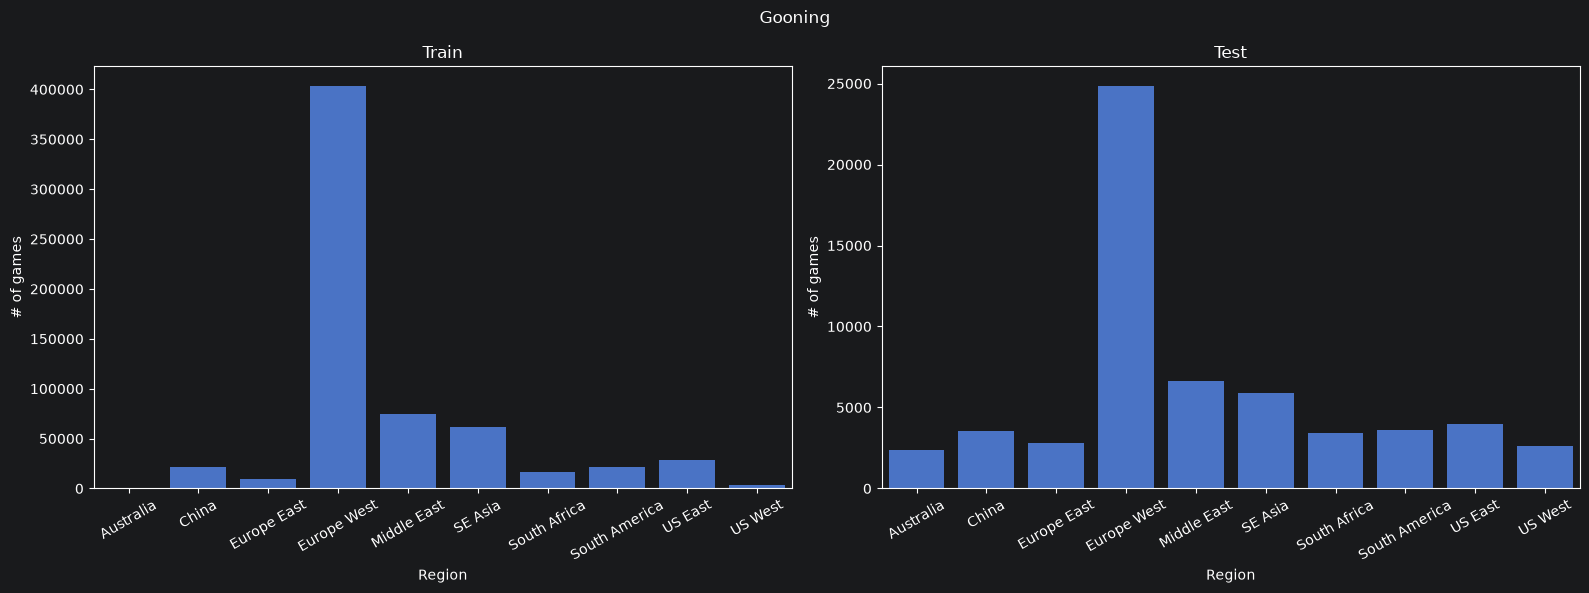

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

regions_games = matches_train.groupby(['region'])['region'].count()
regions_games_t = matches_test.groupby(['region'])['region'].count()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))


sns.barplot(x=regions_games.index, y=regions_games.values, ax=axes[0])
axes[0].set_title('Train')
axes[0].set_ylabel('# of games')

sns.barplot(x=regions_games_t.index, y=regions_games_t.values)
axes[1].set_title('Test')
axes[1].set_ylabel('# of games')

for ax in axes:
    ax.set_xlabel('Region')
    ax.tick_params(axis='x', rotation=30)

fig.suptitle('Gooning')
fig.tight_layout()
plt.show()

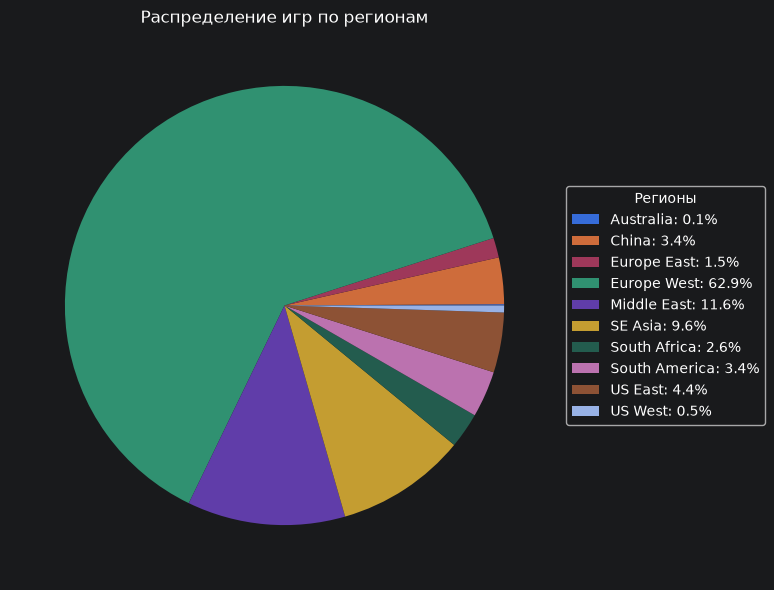

In [9]:
plt.figure(figsize=(10, 6))

wedges, _ = plt.pie(regions_games.values)

labels = [
    f'{region}: {count / regions_games.sum():.1%}'
    for region, count in regions_games.items()
]

plt.legend(
    wedges,
    labels,
    title='Регионы',
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)

plt.title('Распределение игр по регионам')
plt.tight_layout()
plt.show()

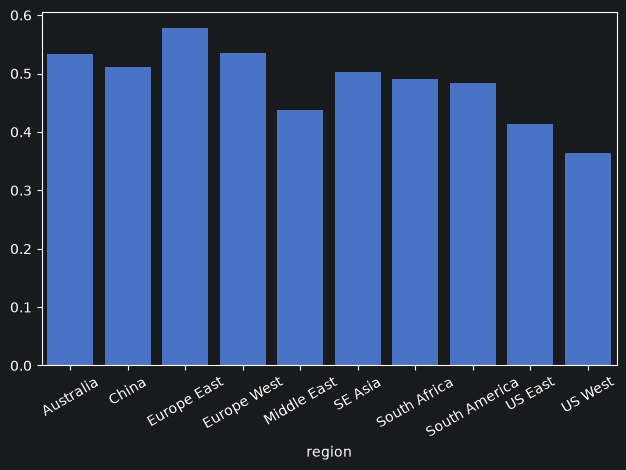

In [10]:
import numpy as np
mean_win = matches_train.groupby(['region'])['radiant_win'].mean()

sns.barplot(x=mean_win.index, y=mean_win.values)
plt.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что вы можете сказать о распределении регионов? Объясните, получится ли вообще обучить по нему модель, есть ли там сигнал?

**Ответ:** Матчи распределены по регионам неравномерно. В регионах США выборки небольшие, поэтому видимые отличия в доле побед могут быть шумом. На Ближнем Востоке доля побед чуть ниже, но по одному графику сложно оценить, насколько полезен этот признак.
</div>

Наша первая развилка — <font color="#cb9255">**выбор**</font>, какой из энкодеров стащить. Рекомендуется брать что-то из `category_encoders`, они похожи на стандартные из `sklearn`, но их больше и применять их проще.

| <font color="#cb9255">**One-Hot Encoder**</font> | <font color="#cb9255">**Target Encoder**</font> |
| :--- | :--- |
| Превращает категориальный признак в вектор из 0 и 1.  <br> 1 стоит на месте i‑го индекса, если у объекта есть i‑е значение признака. | Кодирует категориальный признак средним значением таргета.  <br> Среднее считается по всем объектам с i‑м значением признака. |

Можно взять и другой, но морально готовьтесь получить $\text{Gini} = 0$
</div>

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Без энкодинга использовать категориальные признаки в линейных моделях, увы, нельзя, выбор без выбора 

</div>

In [11]:
!pip install -qU category-encoders


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** какой из энкодеров кажется вам наиболее привлекательным? Почему?

**Ответ:** Для начала я выбрал OHE: категорий немного, и такое кодирование проще интерпретировать. Target encoding можно проверить отдельно.
</div>

Закодируйте колонку `region` выбранным вами способом




In [12]:
matches_test['date'] = pd.to_datetime(matches_test['date'])
matches_train['date'] = pd.to_datetime(matches_train['date'])

In [13]:
X_matches_train = matches_train.drop(columns=['radiant_win'])
y_matches_train = matches_train['radiant_win']

In [14]:
import category_encoders as ce

encoder = ce.OneHotEncoder(
    cols=['region'],
    use_cat_names=True
)

In [15]:
matches_train_encoded = encoder.fit_transform(matches_train)

#### **Задание 1.3. Даты** (1.25 балла)

Если нам хочется видеть будущее, именно время диктует, что брать можно, а что никак нельзя

Найдите колонку дат на тренировочных данных и:
1. Постройте график доли побед Radiant в зависимости от даты матча
2. Сравните временные диапазоны на трейне и тесте

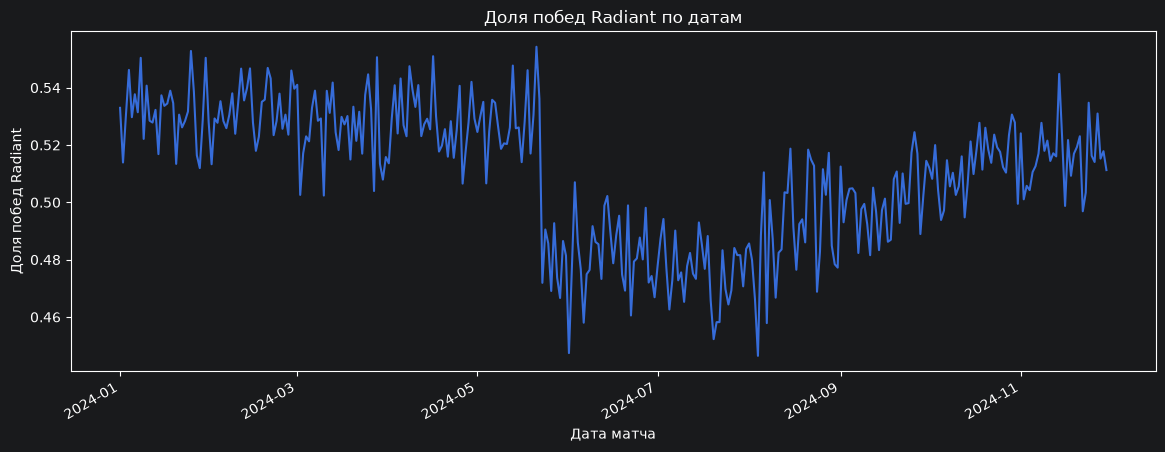

In [16]:
matches_train['date'] = pd.to_datetime(matches_train['date'])

winrate = matches_train.groupby('date')['radiant_win'].mean().reset_index(name='winrate')

fig, ax = plt.subplots(figsize=(14, 5))

sns.lineplot(
    data=winrate,
    x='date',
    y='winrate',
    ax=ax
)

ax.set_xlabel('Дата матча')
ax.set_ylabel('Доля побед Radiant')
ax.set_title('Доля побед Radiant по датам')
fig.autofmt_xdate()
plt.show()

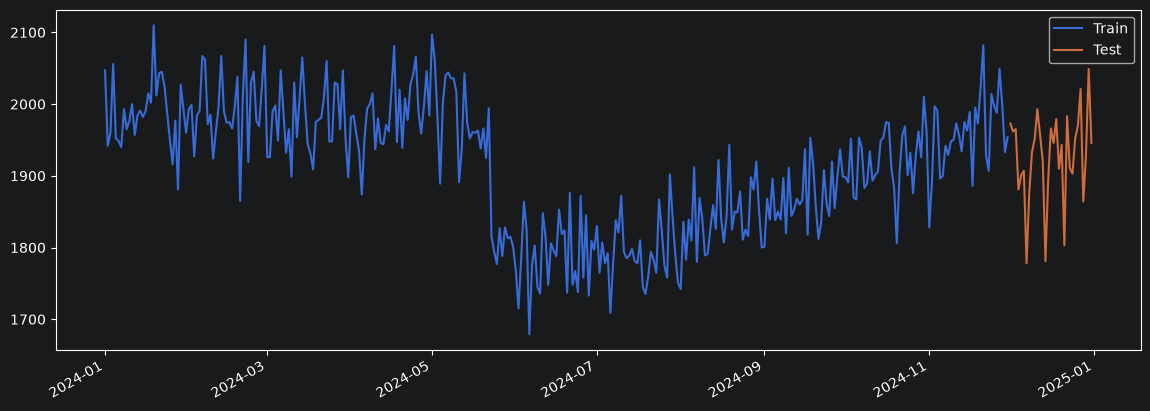

In [17]:
games_data = (
    matches_train.set_index('date')['match_id']
    .resample('D').count()
)
games_data_t = (
    matches_test.set_index('date')['match_id']
    .resample('D').count()
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(games_data.index, games_data.values, label='Train')
ax.plot(games_data_t.index, games_data_t.values, label='Test')

ax.legend()
fig.autofmt_xdate()
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** видите ли вы какой-то паттерн в распределении дат? Можете ли вы объяснить при помощи сети Интернет, что там произошло? \
(Подсказка: соревновательные игры периодически обновляются)

**Ответ:** На графике видна просадка числа матчей. Возможно, она связана с обновлением и изменением игровой меты. В остальные периоды число матчей относительно стабильно и колеблется вокруг обычного уровня.

</div>

Теперь давайте что-нибудь повыделяем.

<div style="border-left: 5px solid #5584a8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Даты сами по себе это всегда очень простые фичи, функционал есть в любой библиотеке. Связь с таргетом может быть, но не обязана. Именно даты проверить легко и быстро, зависимости бывают неожиданными. Впрочем, это не единственная причина, не переключайтесь

</div>

С таймстемпом можно делать не так много, кроме базовых манипуляций:

1. Вытащите лежащую на поверхности информацию, например, день и день недели. Хватит и этих двух
2. Посмотрите сами на список возможных признаков, будь то [pandas](https://pandas.pydata.org/docs/user_guide/timeseries.html#time-date-components) или [polars](https://docs.pola.rs/api/python/stable/reference/expressions/temporal.html), и <font color="#cb9255">**либо добавьте**</font> 2 признака, которые, как вам кажется, сработают, <font color="#cb9255">**либо поясните**</font>, почему это ничего не даст

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** необходимо ли кодировать признаки из дат? Если да, то какие и как? Если нет, то почему? </font>

**Ответ:** По графикам я не вижу устойчивой зависимости винрейта от дня недели, дня месяца или месяца. Отдельно выделяется период просадки числа матчей. День недели всё же попробую как категориальный признак и проверю его вклад на валидации.

</div>

3. Закодируйте новые признаки, согласно вашему ответу

<Axes: xlabel='date'>

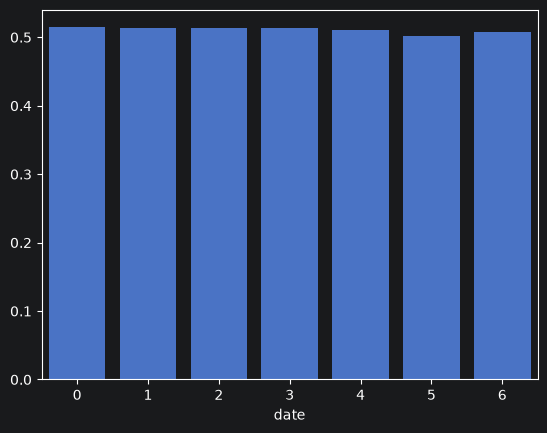

In [18]:
day = matches_train['date'].dt.day
day_of_week = matches_train['date'].dt.dayofweek
counts = (
    matches_train.groupby(matches_train['date'].dt.dayofweek)
    ['radiant_win']
    .mean()
    .reindex(range(7), fill_value=0)
)

sns.barplot(x=counts.index, y=counts.values)

<Axes: xlabel='date'>

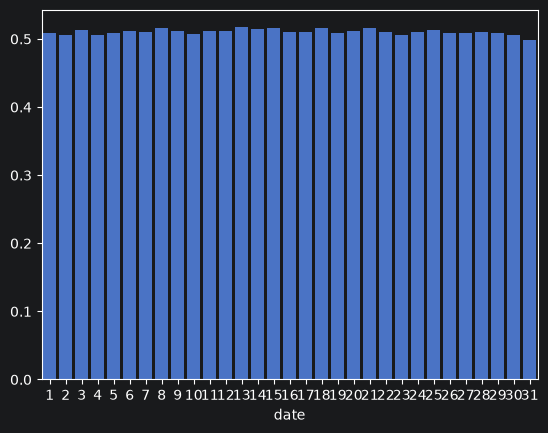

In [19]:
counts = (
    matches_train.groupby(matches_train['date'].dt.day)
    ['radiant_win']
    .mean()
    .reindex(range(1, 32), fill_value=0)
)

sns.barplot(x=counts.index, y=counts.values)

<Axes: xlabel='date'>

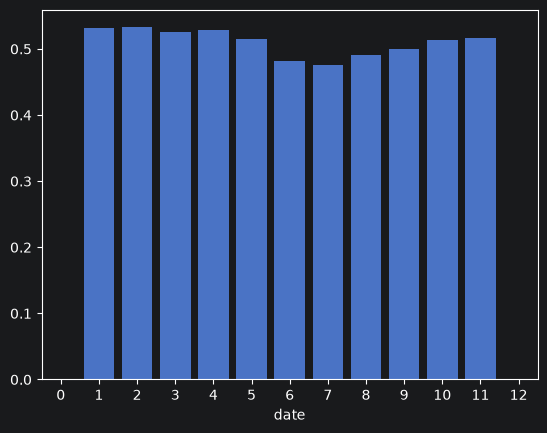

In [20]:
counts = (
    matches_train.groupby(matches_train['date'].dt.month)
    ['radiant_win']
    .mean()
    .reindex(range(13), fill_value=0)
)

sns.barplot(x=counts.index, y=counts.values)

In [21]:
matches_train['day_of_week'] = day_of_week

Кажется, мы что-то забыли... Ах да, надо бы и модель обучить, вот только без валидации это будет как-то не по-моповски, надо озаботиться этим вопросом.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

На самом деле временная структура нужна не столь, чтобы вытащить какие-то признаки, сколько, чтобы понять распределение и изменение данных во времени же. Даты играют в этом прямую роль

</div>

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** почему здесь будет не лучшим решением брать случайное разбиение на трейн и валидацию?

**Ответ:** Распределение матчей и состав регионов могут меняться со временем. Случайное разбиение перемешает ранние и поздние матчи, а временная валидация покажет, как модель работает на более поздних матчах.

</div>

Тут выбор у вас решили отобрать, делать мы будем OOT валидацию. Впрочем, какие-то опции ещё остались

<table width="800" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="50%">
      <font color="#cb9255">OOT (Out-of-Time)</font>
    </th>
    <th width="50%">
      <font color="#cb9255">CV OOT (Cross-Validation Out-of-Time)</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Валидация с одной отложенной подвыборкой, <br>
      взятой после трешхолда t. Простая, как палка, <br>
      но если валидация получится грустной — <br>
      аномальной, нетипичной, маленькой, — <br>
      то и метрика ваша тоже будет грустной.
    </td>
    <td valign="top">
      Кросс-валидация с k разбиениями по времени <br>
      с итеративным расширением исходного фолда. <br>
      Оценка метрики сместится куда меньше <br>
      по сравнению с плохим сплитом OOT, <br>
      но это долго, если фолдов много.
    </td>
  </tr>
  <tr>
    <td valign="top">
      <code>sklearn.model_selection.train_test_split</code>
    </td>
    <td valign="top">
      <code>sklearn.model_selection.TimeSeriesSplit</code>
    </td>
  </tr>
</table>



Настройте любой из видов валидации (<font color="#cb9255">**трешхолд**</font> `t` или <font color="#cb9255">**число фолдов**</font> <code>n_folds</code></font> подберите сами). Они оба должны показывать качество адекватно, хотя второй теоретически должен быть более обоснован. CV-OOT не даст вам бонусов, но кто знает, за какие крохи Джини придётся бороться на соревновании?

In [22]:
from sklearn.model_selection import TimeSeriesSplit

cv = TimeSeriesSplit(n_splits=5)

И вот теперь мы уже наконец-то будем что-то обучать. Моделей классификации мы знаем как минимум две — SVM и логистическую регрессию, но есть нюанс.


Выборы, выборы..:

<table width="800" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="50%">
      <font color="#cb9255">Dedicated model</font>
    </th>
    <th width="50%">
      <font color="#cb9255">Gradient Descent</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Большой разницы между <code>LogisticRegression</code> и <code>LinearSVC</code> <br>
      из <code>sklearn.linear_model</code> на самом деле нет: <br>
      разделяющие поверхности очень похожи, <br>
      оба хорошо оптимизированы специальными солверами.
    </td>
    <td valign="top">
      Градиентный спуск через <code>sklearn.linear_model.SGDClassifier</code> <br>
      с параметрами <code>loss="log_loss"</code> или <code>loss="hinge"</code> — <br>
      очень соблазнительная альтернатива, но!
    </td>
  </tr>
  <tr>
    <td valign="top">
      <font color="#cb9255"><b>+</b></font> Обучать и применять их в разы проще, <br>
      фит–предикт делает брр. <br>
      <font color="#cb9255"><b>−</b></font> Они используют сразу всю выборку <br>
      для обучения, а в ходе задания наша выборка <br>
      может вырасти раз так в 1000, немало!
    </td>
    <td valign="top">
      <font color="#cb9255"><b>+</b></font> Влезет любой датасет. <br>
      <font color="#cb9255"><b>+</b></font> Бóльший контроль над процессом обучения. <br>
      <font color="#cb9255"><b>−</b></font> Обучать на больших данных <br>
      (скорее про часть <b>advanced</b>) придётся через <code>partial_fit</code>, неудобно. <br>
      <font color="#cb9255"><b>−</b></font> Нужно подбирать больше гиперпараметров.
    </td>
  </tr>
</table>


Выберите <font color="#cb9255">**одну из**</font> моделей выше (хотя `LinearRegression` <font color="#cb9255">**тоже можно**</font>, если у вас сегодня авантюрное настроение, успех не гарантирован, о рисках узнаете на лекции) **(обращаем внимание, что другие варианты запрещены)**. Обучите по одному экземпляру на группах признаков:

- дат
- регионов
- дат и регионов

Ну и замерьте качество!

<font color="#cb9255">**NB**</font>: 

1. Вы сразу можете строить роскошный пайплайн обучения, а не делать по кускам в отдельных блоках, про это есть **advanced** пункт (**6.1**) на 0.5 баллов
2. Если у вас есть GPU, то почему бы его и не [использовать](https://docs.rapids.ai/api/cuml/stable/)? Если гпу у вас нет, у вас теперь точно есть Kaggle, который щедро дарит 30 часов гпу в неделю, пользуйтесь на здоровье, за это есть маленький, но приятный буст на 0.25 балла (**пункт 6.3**)
3. Наконец, если вы сразу оформите хранилище для результатов запусков ваших моделей, вы снова получите 0.25 балла (**пункт 6.2**)

In [23]:
matches_train

,match_id,date,region,game_mode,duration,radiant_win,avg_mmr,day_of_week
0,1,2024-02-12,Europe West,4,2625,False,3519.7,0
1,2,2024-04-08,South Africa,2,7526,True,2330.9,0
2,3,2024-06-16,SE Asia,1,2831,True,1579.6,6
3,4,2024-09-16,Middle East,22,1438,False,NaN,0
4,5,2024-03-31,South Africa,22,2051,True,NaN,6
...,...,...,...,...,...,...,...,...
641085,767815,2024-07-13,US East,1,1888,False,401.1,5
641086,767817,2024-02-02,China,1,2789,False,NaN,4
641087,767818,2024-07-03,China,2,1197,False,1953.4,2
641088,767820,2024-11-08,Middle East,1,4155,True,NaN,4


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

def make_pipeline(X):
    return Pipeline([
        ('ohe', ce.OneHotEncoder(
            cols=[col for col in ['region'] if col in X.columns]
        )),
        ('model', LogisticRegression(max_iter=1000))
    ])

df = matches_train.copy()
df = df.sort_values('date')

X1 = df[['region']]
X2 = df[['day_of_week']]
X3 = df[['day_of_week', 'region']]
y = df['radiant_win']


scores1 = cross_val_score(
    make_pipeline(X1), X1, y,
    cv=cv,
    scoring='roc_auc'
)
scores2 = cross_val_score(
    make_pipeline(X2), X2, y,
    cv=cv,
    scoring='roc_auc'
)
scores3 = cross_val_score(
    make_pipeline(X3), X3, y,
    cv=cv,
    scoring='roc_auc'
)


print('Mean Gini 1:', 2 * scores1.mean() - 1)
print('Mean Gini 2:', 2 * scores2.mean() - 1)
print('Mean Gini 3:', 2 * scores3.mean() - 1)
print('diff in folds:', 2 * (scores3 - scores1))

Mean Gini 1: 0.07529387266675736
Mean Gini 2: 0.0070700681062441095
Mean Gini 3: 0.0781806615903331
diff in folds: [0.00173633 0.00483189 0.00390435 0.00239365 0.00156772]


<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** помогли ли даты? А должны? Хотите ли вы их оставить?

**Ответ:** День недели дал небольшой прирост в сочетании с регионом, поэтому я оставлю этот признак.

</div>

#### **Задание 1.4. Числа** (0.75 балла)

Остался неотвеченным лишь один вопрос — а что числовые признаки? С ними всё одновременно и проще, и сложнее.

Найдите, где хранится средний ммр матча — это средний рейтинг игроков, которые в нём участвовали, чем выше, тем лучше.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

От ммра напрямую зависит то, как игроки пользуются естественным преимуществом Radiant. Чем игроки сильнее, тем чаще это должно происходить, в теории

</div>

Сделайте (на трейне, валидации и тесте) вот что :
1. Постройте график распределения ммров
2. Сравните, насколько распределения похожи между собой визуально

<Axes: xlabel='avg_mmr', ylabel='Count'>

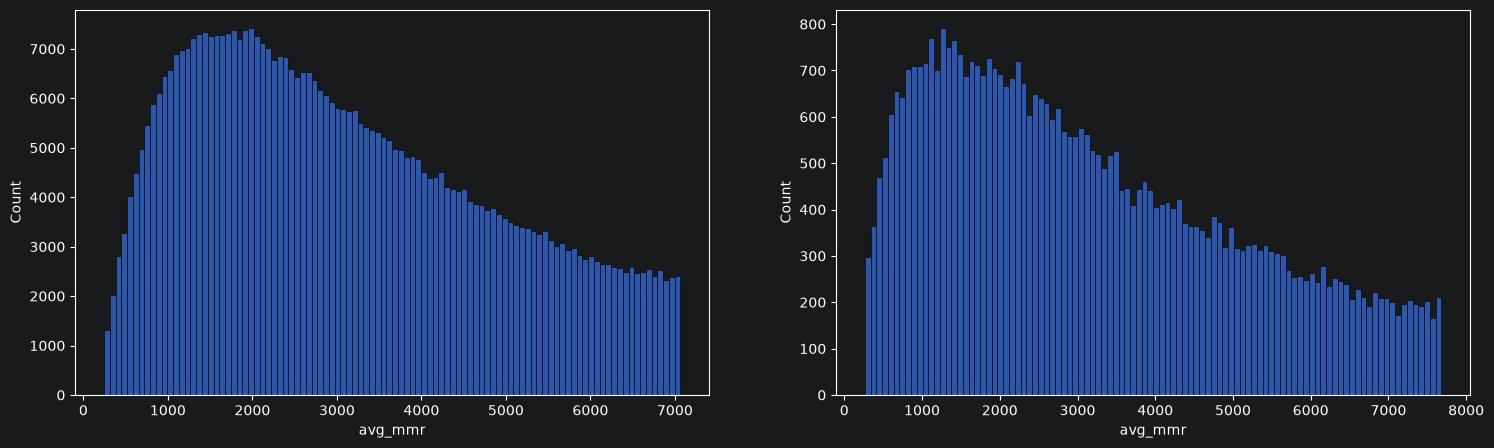

In [25]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

sns.histplot(data=matches_train, x='avg_mmr', bins=100, ax=axs[0])
sns.histplot(data=matches_test, x='avg_mmr', bins=100, ax=axs[1])

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** как бы вы описали это распределение в целом, похоже ли оно на что-то знакомое вам? 

**Ответ:** Распределение похоже на нормальное, но с вытянутым хвостом. Я бы попробовал логарифм или квадратный корень и сравнил результаты.

</div>

Кто-то где-то говорил, что числовые признаки надо бы стандартизировать, чтобы вышло что-то годное. Этот кто-то прав, но как известно, практика — критерий истины

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Но в действительности это зависит от данных. Сходимость итеративных алгоритмов улучшается, но может пострадать качество, особенно, если распределение не нормальное, или есть отличие в $\mu$ и $\sigma$ на тесте
 
Однако даже пара пунктов Джини это довольно хороший буст, вы убедитесь, когда приступите к сореве, за них нужно бороться любой ценой, тем более, что это почти бесплатно

</div>

Так или иначе, у нас и распределение то не нормальное, но, к счастью, это решаемо. Сделайте такие преобразования признака ммров $f_{\text{mmr}}$ и нарисуйте их график:

$$f_{\text{mmr}} \mapsto \log( 1+f_{\text{mmr}} ); \qquad f_{\text{mmr}} \mapsto \sqrt{f_{\text{mmr}}}; \qquad f_{\text{mmr}} \mapsto \frac{1}{1+f_{\text{mmr}}}; \qquad f_{\text{mmr}} \mapsto \exp{\log f_{\text{mmr}}};$$

Затем выберите то, что вам нравится больше всего

,match_id,date,region,game_mode,duration,radiant_win,avg_mmr,day_of_week
0,1,2024-02-12,Europe West,4,2625,False,3519.7,0
1,2,2024-04-08,South Africa,2,7526,True,2330.9,0
2,3,2024-06-16,SE Asia,1,2831,True,1579.6,6
3,4,2024-09-16,Middle East,22,1438,False,NaN,0
4,5,2024-03-31,South Africa,22,2051,True,NaN,6
...,...,...,...,...,...,...,...,...
641085,767815,2024-07-13,US East,1,1888,False,401.1,5
641086,767817,2024-02-02,China,1,2789,False,NaN,4
641087,767818,2024-07-03,China,2,1197,False,1953.4,2
641088,767820,2024-11-08,Middle East,1,4155,True,NaN,4


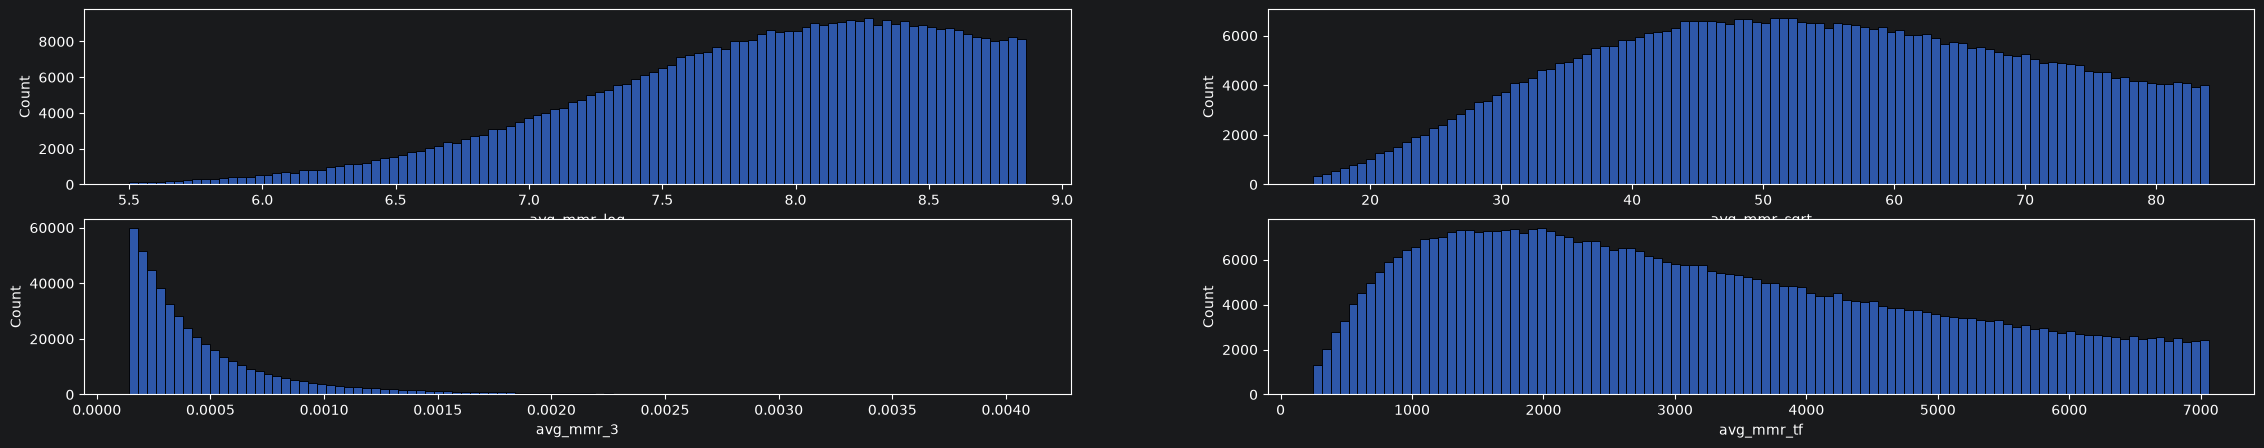

In [26]:
df = matches_train.copy()
df['avg_mmr_log'] = np.log(1 + df['avg_mmr'])
df['avg_mmr_sqrt'] = np.sqrt(df['avg_mmr'])
df['avg_mmr_3'] = 1 / (1 + df['avg_mmr'])
df['avg_mmr_tf'] = np.exp(np.log(df['avg_mmr']))

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(28, 5))
sns.histplot(data=df, x='avg_mmr_log', bins=100, ax=axs[0][0])
sns.histplot(data=df, x='avg_mmr_sqrt', bins=100, ax=axs[0][1])
sns.histplot(data=df, x='avg_mmr_3', bins=100, ax=axs[1][0])
sns.histplot(data=df, x='avg_mmr_tf', bins=100, ax=axs[1][1])



matches_train

Мы как-то раньше не обращали внимание, но шестое чувство подсказывает, что в ммрах есть пропуски. Выкинуть их не получится, потому что на тесте они тоже есть, поэтому выход один — чем-то заполнять.


<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

А пропуски у нас есть, потому что не все игры рейтинговые, там информацию по ммру собрать не удастся

В категориальных признаках пропуски не так важны для линрега, их можно закодировать специальной категорией. В числовых проигнорировать их не получится

В любом случае, лучше дополнительно добавить признак-флаг `mmr_missing`, который говорит, что пропуск там на самом деле есть. <font color="#cb9255">**Можете**</font> замерить его влияние, если есть желание, вдруг мы советуем полную дичь и там Джини 0.9?

</div>

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** нормально ли в данном случае заполнить пропуски нулём? А чем тогда, если нет?

**Ответ:** Нулевой MMR мог бы выглядеть для модели как крайне низкий реальный рейтинг. Я бы заполнил пропуски медианой, рассчитанной на обучающей выборке.

</div>

Момент истины. Обучите две новые модели: к оптимальному набору фичей из предыдущего пункта добавьте в одном случае фичу без преобразования, а в другом — после преобразования. Зацените эффект на трейне и на валидации


<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Помните, что как бы ни было прекрасно и информативно преобразование в вашей голове, ключевое это перформанс на отложенной выборке \
В жизни каждого дата-сайентиста бывает такое, что фича, которая ну должна быть клёвой, <i>математически</i>, на практике оказывается той ещё жижей, и такое, увы, тоже нужно отслеживать

</div>

In [27]:
from sklearn.impute._base import SimpleImputer

df = matches_train.copy().sort_values('date')

df['mmr_missing'] = df['avg_mmr'].isna().astype(int)
df['avg_mmr'] = np.sqrt(df['avg_mmr'])

X = df[['region', 'day_of_week', 'mmr_missing', 'avg_mmr']]
y = df['radiant_win']


df['avg_mmr'] = np.square(df['avg_mmr'])
X_def = df[['region', 'day_of_week', 'mmr_missing', 'avg_mmr']]

pipeline = Pipeline([
    ('ohe', ce.OneHotEncoder(cols=['region'])),
    ('imputer', SimpleImputer(strategy='median')),
    ('model', LogisticRegression(max_iter=1000))
])

scores = cross_val_score(
    pipeline, X, y,
    cv=cv,
    scoring='roc_auc'
)

scores_def = cross_val_score(
    pipeline, X_def, y,
    cv=cv,
    scoring='roc_auc'
)

print("GINI: ", 2 * scores.mean() - 1)
print("GINI_def: ", 2 * scores_def.mean() - 1)

/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


GINI:  0.1480111016700718
GINI_def:  0.14718467185507933


In [28]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler, FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def add_features(X):
    X = X.copy()
    X['day_of_week'] = pd.to_datetime(X['date']).dt.dayofweek
    X['mmr_missing'] = X['avg_mmr'].isna().astype(int)
    return X

df = matches_train.copy()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
X_main_train = df.drop(columns='radiant_win')
y_main_train = df['radiant_win']

X_main_test = matches_test.copy()

mmr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('sqrt', FunctionTransformer(np.sqrt)),
    ('scaling', StandardScaler())
])

column_transformer = ColumnTransformer([
    ('ohe', ce.OneHotEncoder(cols=['region', 'day_of_week']), ['region', 'day_of_week']),
    ('mmr', mmr_pipeline, ['avg_mmr']),
    ('flags', 'passthrough', ['mmr_missing'])
], remainder='drop')

pipeline = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('column_transformer', column_transformer),
    ('model', LogisticRegression(max_iter=1500))
])

In [29]:
X_matches_train

,match_id,date,region,game_mode,duration,avg_mmr
0,1,2024-02-12,Europe West,4,2625,3519.7
1,2,2024-04-08,South Africa,2,7526,2330.9
2,3,2024-06-16,SE Asia,1,2831,1579.6
3,4,2024-09-16,Middle East,22,1438,NaN
4,5,2024-03-31,South Africa,22,2051,NaN
...,...,...,...,...,...,...
641085,767815,2024-07-13,US East,1,1888,401.1
641086,767817,2024-02-02,China,1,2789,NaN
641087,767818,2024-07-03,China,2,1197,1953.4
641088,767820,2024-11-08,Middle East,1,4155,NaN


In [30]:
score = cross_val_score(
    pipeline, X_main_train, y_main_train,
    cv=cv,
    scoring='roc_auc'
)

print("GINI: ", 2 * score.mean() - 1)

GINI:  0.14796500224694364


### **Часть 2. Векторы** (1.5 балла) <img align="center" height=28 width=28 src="https://static.wikia.nocookie.net/dota2_gamepedia/images/1/17/Emoticon_sick.gif/revision/latest?cb=20180504011850">

В которой студент испытывает вьетнамские флешбеки от дз1, фиксит чужие баги и делает нереально мощную фичу, которую можно полировать до посинения

#### **Задание 2.1. Большая чистка** (0.75 балла)

Пока что мы никак не использовали информацию про героев, а ведь от них напрямую зависит исход матча, их больше 100 штук и все они разные: кто-то сильнее, кто-то слабее, а кто-то красивее :3. Только в данные кто-то нагадил, придётся убирать! Тут придётся ещё разочек освежить `pandas`/`polars`

Датасеты, которые нас интересуют теперь — `player_df.csv` и `Constants.Heroes.csv`. Там есть и данные на трейне, и на тесте, мы их обязательно приджойним, но потом.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Данные, как и стойло, необходимо чистить. Ранее нам везло и в целом каких-то извращений мы не наблюдали, да и тут сходу не увидим. Т.н. *"выбросы"* это, во-первых, тема отдельного холивара, а во-вторых история про доменное несоответствие, матстат такое не найдёт, но на то у нас есть мозг, верно?

Под доменом имеется в виду контекст, в котором создаются ваши данные, и процессы которого ваши данные описывают (в нашем случае — то, как устроена игра и баланс в ней). Тогда выброс — это то, что в контекст не вписывается, даже если ошибки там нет. Про это весь пункт

</div>

Первое, что нужно отсмотреть - главные ключи. Начнём с игроков. Повертите `account_id`, вас должны смутить как минимум два айдишника.


<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Не все игроки делают свой профиль публичным, их айди в таком случае будет анонимизирован

Небольшая часть данных собрана некорректно, айди таких игроков тоже помечен особенным значением

</div>

<Axes: xlabel='account_id', ylabel='Count'>

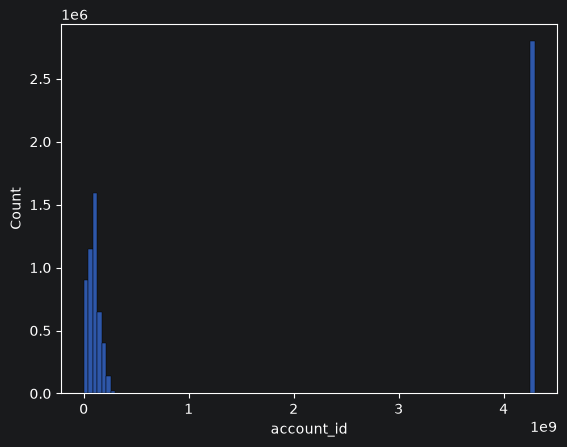

In [31]:
sns.histplot(data=players, x='account_id', bins=100)

In [32]:
players.value_counts('account_id')

account_id
 4294967295    2795673
-1               27267
 37619671          801
 84244723          763
 87266522          761
                ...   
 75278128            1
 198435393           1
 156405264           1
 103714666           1
 114328757           1
Name: count, Length: 974931, dtype: int64

In [33]:
players.shape

(7650825, 14)

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** можем ли мы себе позволить выкинуть матчи с какими-либо подозрительными айди без большого ущерба данным?

**Ответ:** Похоже, `-1` и `4294967295` — служебные значения `account_id`. Их точный смысл по данным неясен. Я бы сохранил строки, если остальные поля корректны, и исключил эти значения из проверок уникальности известных аккаунтов.

</div>

Следующий логический шаг — одинаковых героев быть в одном матче не должно.  

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

В кастомных, т.е. не основных режимах игры, это может быть не так, но нас они не интересуют

</div>

Найдите, есть ли игры, в которых это по какой-то причине не так. Если таких матчей не слишком много, избавьтесь от них

In [34]:
players = pd.read_csv('player_df.csv')
players = players.drop_duplicates()

match_ids = pd.Index(pd.concat([
    matches_train['match_id'], matches_test['match_id']
]).unique())
players = players.loc[players['match_id'].isin(match_ids)].copy()

duplicate_hero_rows = players.duplicated(['match_id', 'hero_id'], keep=False)
bad_hero_matches = players.loc[duplicate_hero_rows, 'match_id'].unique()
countsBad = (
    players.loc[duplicate_hero_rows]
    .groupby(['match_id', 'hero_id']).size().reset_index(name='count')
)

players = players.loc[~players['match_id'].isin(bad_hero_matches)].copy()
matches_train = matches_train.loc[
    ~matches_train['match_id'].isin(bad_hero_matches)
].copy()

Вы могли заметить героя-импостера под индексом 0. Если вы посмотрите в `Constants.Heroes.csv`, то его там не найдёте, потому что это тоже ошибка.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Скорее всего это те, кто не успел выбрать героя, игра могла просто не начаться

Вряд ли у нас получится заполнить пропуски чем-то адекватным — они зависят от игрока и героя, переменных много. Попробовать можно, но точно не в базовой части

</div>

Финальным аккордом:

- посмотрите, что за игроки играли на герое с `hero_id=0`, и выкиньте такие матчи вместе со всеми пропусками
- найдите игроков, которые в одном матче играли одновременно и за команду сил Тьмы (слоты `{128, ..., 132}`), и за команду сил Света (слоты `{0, ..., 4}`), не являясь подозрительными айди из пункта выше, уберите их
- отфильтруйте `player_df`, оставьте только те матчи, которые есть в наших выборках
- проверьте, что в каждом матче ровно 5 игроков за Свет и ровно 5 за Тьму

Можно в любом порядке, но эти вещи нужно проверить, они поломают следующий пункт

In [35]:
invalid_hero = players['hero_id'].isna() | ~players['hero_id'].isin(heroes['id'])
valid_slots = [0, 1, 2, 3, 4, 128, 129, 130, 131, 132]
invalid_slot = ~players['player_slot'].isin(valid_slots)
bad_matches = players.loc[invalid_hero | invalid_slot, 'match_id'].unique()

players = players.loc[~players['match_id'].isin(bad_matches)].copy()
matches_train = matches_train.loc[
    ~matches_train['match_id'].isin(bad_matches)
].copy()

In [36]:
known_account = (
    players['account_id'].notna()
    & ~players['account_id'].isin([-1, 4294967295])
)
account_sides = (
    players.loc[known_account, ['match_id', 'account_id', 'player_slot']]
    .assign(
        radiant=lambda p: p['player_slot'].isin(range(5)),
        dire=lambda p: p['player_slot'].isin(range(128, 133))
    )
    .groupby(['match_id', 'account_id'])[['radiant', 'dire']].max()
)
bad_account_pairs = account_sides.loc[
    account_sides['radiant'] & account_sides['dire']
].reset_index()
bad_accounts = bad_account_pairs['account_id'].unique()
bad_account_matches = bad_account_pairs['match_id'].unique()

players = players.loc[~players['match_id'].isin(bad_account_matches)].copy()
matches_train = matches_train.loc[
    ~matches_train['match_id'].isin(bad_account_matches)
].copy()

In [37]:
match_ids = pd.concat([
    matches_train['match_id'],
    matches_test['match_id']
]).unique()


players = players[players['match_id'].isin(match_ids)]

In [38]:
team_counts = (
    players.assign(
        radiant=players['player_slot'].isin(range(5)),
        dire=players['player_slot'].isin(range(128, 133))
    )
    .groupby('match_id')
    .agg(
        total=('player_slot', 'size'),
        radiant=('radiant', 'sum'),
        dire=('dire', 'sum'),
        slots=('player_slot', 'nunique'),
        heroes=('hero_id', 'nunique')
    )
    .reindex(match_ids, fill_value=0)
)

bad_compositions = team_counts.loc[
    (team_counts['total'] != 10)
    | (team_counts['radiant'] != 5)
    | (team_counts['dire'] != 5)
    | (team_counts['slots'] != 10)
    | (team_counts['heroes'] != 10)
]

players = players.loc[
    ~players['match_id'].isin(bad_compositions.index)
].copy()
matches_train = matches_train.loc[
    ~matches_train['match_id'].isin(bad_compositions.index)
].copy()

In [39]:
players.isna().any(axis=1).sum()

np.int64(596460)

Если вас всё же одолевает паранойя, то ~~я вас понимаю~~ будьте уверены, что если проблемы в `player_df` и остались, на модель они повлияют минимально. Ну а идеала не бывает нигде

#### **Задание 2.2. Энкодер героев** (0.75 балла)

А зачем мы вообще этим занимаемся? Вопрос хороший. План был в том, чтобы закодировать комбинации героев, которые участвуют в матче. Это чуть более сложный признак, чем обычный трансформ, тут придется поколдовать.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Идея в том, что какие-то комбинации героев эффективнее других. Если понять, что в матче за персонажи, можно сразу же прикинуть шансы на победу одной из сторон

</div>

Ваша задача - закодировать каждый матч вектором вида:

| match_id | hero_1 | hero_2 | hero_3 | ... | hero_n |
| --- | --- | --- | --- | --- | --- |
| 228 | 1 | 0 | -1 | ... | 0 |

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Потом <font color="#cb9255">**можно**</font> бахнуть One-Hot и разбить героев на две команды, если не боитесь переобучения. Вещь необязательная

</div>

Потребуются таблицы `player_df.csv` и `matches_df_*.csv`. Для удобства может пригодиться `Constants.Heroes.csv` (индексы оттуда и в `player_df` верные, по ним можно джойнить, но они идут не по порядку, не смотрите на пандасовский айди).

Хочется видеть либо функцию, либо в идеале класс, который вертит фичами вот так:

Каждый элемент в векторе матча `(hero_1, ..., hero_n)` принимает значение 1, если герой был в команде сил Света (слоты `{0, ..., 4}`), и -1, если в команде сил Тьмы (слоты `{128, ..., 132}`). 

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Класс нужен, поскольку при неаккуратной реализации есть риск не влезть в память при трансформе целого датасета. Главное, чтобы была функция, а там можно применять её на батч. 

Либо же <font color="#cb9255">**можете**</font> преисполниться спарс матрицами, которые экономно (не) хранят миллионы нулей. Вещь несложная и полезная

</div>

Реализуйте то, что написано

In [49]:
import numpy as np
import pandas as pd

from scipy.sparse import csr_array
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class HeroesEncoder(TransformerMixin, BaseEstimator):
    def __init__(self, players, hero_ids):
        self.players = players
        self.hero_ids = hero_ids

    def fit(self, X, y=None):
        self.hero_index_ = pd.Index(self.hero_ids)

        return self

    def transform(self, X):
        check_is_fitted(self, 'hero_index_')

        match_index = pd.Index(X['match_id'])

        p = self.players.loc[
            self.players['match_id'].isin(match_index),
            ['match_id', 'hero_id', 'player_slot']
        ]

        rows = match_index.get_indexer(p['match_id'])
        cols = self.hero_index_.get_indexer(p['hero_id'])

        radiant = p['player_slot'].isin(range(5)).to_numpy()

        values = np.where(radiant, 1, -1).astype(np.int8)

        sparse_mx = csr_array(
            (values, (rows, cols)),
            shape=(len(match_index), len(self.hero_index_))
        )
        sparse_mx.indices = sparse_mx.indices.astype(np.int32, casting='same_kind')
        sparse_mx.indptr = sparse_mx.indptr.astype(np.int32, casting='same_kind')

        return sparse_mx

Осталось лишь самое сладкое — проверить фичу в деле. Обучите две модели: одну со всеми фичами, что мы накрутили, и одну только с фичами героев, покажите качество

In [50]:
hero_ids = heroes['id'].dropna().unique()

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler, FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def add_features(X):
    X = X.copy()
    X['day_of_week'] = pd.to_datetime(X['date']).dt.dayofweek
    X['mmr_missing'] = X['avg_mmr'].isna().astype(int)
    return X

mmr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('sqrt', FunctionTransformer(np.sqrt)),
    ('scaling', StandardScaler())
])

column_transformer = ColumnTransformer([
    ('ohe', ce.OneHotEncoder(cols=['region', 'day_of_week']), ['region', 'day_of_week']),
    ('mmr', mmr_pipeline, ['avg_mmr']),
    ('flags', 'passthrough', ['mmr_missing']),
    ('heroes', HeroesEncoder(players=players, hero_ids=hero_ids), ['match_id'])
], remainder='drop')

pipeline = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('column_transformer', column_transformer),
    ('model', LogisticRegression(max_iter=1500))
])

In [51]:
df = matches_train.copy()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

X_main_train = df.drop(columns='radiant_win')
y_main_train = df['radiant_win']


score = cross_val_score(
    pipeline, X_main_train, y_main_train,
    cv=cv,
    scoring='roc_auc'
)

print('Gini: ', 2 * score.mean() - 1)

Gini:  0.3050141064777754


Итого у вас должно получиться что-то на уровне $\text{Gini} = 0.25$ на тесте, а может даже выше

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Вы могли заметить, что прирост получится не таким значительным, как можно было ожидать, хотя признак сильный. Чем больше добавлять хороших признаков, тем лучше и лучше они объясняют данные.

Даже сложный и хороший по отдельности признак в комбинации с другими будет давать всё меньшее качество. Отчасти это объясняется мультиколлинеарностью, отчасти природой данных, некоторые из них просто слишком сложны

</div>

### **Часть 3. Оптимизация для уже смешариков (1.25 балла)** <img height=28 width=28 align="center" src="https://cdn.7tv.app/emote/01H8RPMSBR000133946WK71YXM/1x.avif">

В которой студент изучает, как оптимизировать модель **по-взрослому**

#### **Задание 3.1. Optuna для самых маленьких** (0.75 балла)

Не стоит забывать, что у любой модели есть <font color="#cb9255">**гиперпараметры**</font>. Конечно, львиная доля качества будет идти от фичей, но списывать параметры со счетов не стоит. В конце концов, бывает, что с безнадёжным на первый взгляд набором признаков, оптимизированная модель покажет лучшее качество, чем базовая модель на топовых фичах, вот и посмотрим.
<a id="section"></a>

Для эффективного подбора гиперпараметров существует несколько решений, основанных на байесовской оптимизации. Одно из наиболее удобных — [optuna](https://optuna.org/), которая делает перебор гиперпараметров таким же лёгким и увлекательным занятием, как составление домашек по МО.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Идея — смоделировать, какой набор гиперпараметров даст лучшее качество там, где перспективнее, на основе истории их подбора (подробнее на МО2)

</div>

Напишите функцию оптимизации для вашего классификатора. Можете воспользоваться шаблоном ниже, но он довольно куцый, курите документацию. Раз уж инструмент новый, начнём с чего-то простого. Подберите вот такие гиперпараметры (посмотрите на них, прежде, чем тюнить, у них разные диапазоны и разный же смысл (логарифмическая шкала — наш лучший друг, возможно даже лучше настоящих)):

1) Численный — `alpha` у `SGDClassifier` или параметр регуляризации `C` у всех остальных.
2) Категориальный — `solver` у `LogisticRegression`, `loss` у всех остальных
3) Число итераций — `max_iter`. Это не совсем гиперпараметр, но поверьте, обучать модель 100 лет вы не хотите, к тому же это вид неявной регуляризации

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Раз уж все алгоритмы у нас итерационные, от того, как и по какой функции оптимизироваться, довольно важно

Способов применять оптуну вновь два. Выбор, как всегда, в ваших руках:\
<font color="#cb9255">**Первое**</font> — тестить после каждой фичи, это точнее, но можем переобучиться. <font color="#cb9255"> \
**Второе**</font> — подобрать параметры один раз, это проще, но зато быстро. У нас модель простая и перебирать там можно мало чего, пока что, во второй части параметров станет больше. \

</div>

In [52]:
import optuna


def objective(trial):
    params = {
        # смотрите доку
    }
    C = trial.suggest_float('C', 1e-4, 1e3, log=True)
    solver = trial.suggest_categorical(
        'solver',
        ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
    )
    max_iter = trial.suggest_int('max_iter', 1000, 3000, step=500)

    pipeline = Pipeline([
        ('features', FunctionTransformer(add_features)),
        ('column_transformer', column_transformer),
        ('model', LogisticRegression(max_iter=max_iter, C=C, solver=solver)),
    ])
    score = cross_val_score(
        pipeline, X_main_train, y_main_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=1
    )

    gini_valid = 2 * score.mean() - 1
    
    return gini_valid


study = optuna.create_study(direction="maximize")

study.optimize(objective, show_progress_bar=True, n_trials=25)

[I 2026-11-13 19:21:36,568] A new study created in memory with name: no-name-bc9418a8-012d-40dc-ab73-77395c0e2e59
Best trial: 0. Best value: 0.304957:   4%|▍         | 1/25 [00:05<02:06,  5.26s/it]

[I 2026-11-13 19:21:41,824] Trial 0 finished with value: 0.3049567024866866 and parameters: {'C': 0.006770143386722034, 'solver': 'lbfgs', 'max_iter': 1000}. Best is trial 0 with value: 0.3049567024866866.


Best trial: 1. Best value: 0.305018:   8%|▊         | 2/25 [00:10<02:05,  5.46s/it]

[I 2026-11-13 19:21:47,433] Trial 1 finished with value: 0.30501839708426126 and parameters: {'C': 0.4612910488179155, 'solver': 'newton-cg', 'max_iter': 2000}. Best is trial 1 with value: 0.30501839708426126.


Best trial: 2. Best value: 0.305029:  12%|█▏        | 3/25 [00:50<07:45, 21.15s/it]

[I 2026-11-13 19:22:27,254] Trial 2 finished with value: 0.30502943549774786 and parameters: {'C': 0.0394100639943984, 'solver': 'saga', 'max_iter': 1500}. Best is trial 2 with value: 0.30502943549774786.


... (40 outputs left out)

Best trial: 19. Best value: 0.30503:  96%|█████████▌| 24/25 [3:51:44<15:59, 959.84s/it] 

[I 2026-11-13 23:13:21,281] Trial 23 finished with value: 0.30020939686658776 and parameters: {'C': 0.00044265399786499673, 'solver': 'saga', 'max_iter': 1000}. Best is trial 19 with value: 0.3050303146268838.


Best trial: 19. Best value: 0.30503: 100%|██████████| 25/25 [3:52:03<00:00, 556.93s/it]

[I 2026-11-13 23:13:39,832] Trial 24 finished with value: 0.30492553138606504 and parameters: {'C': 0.005690998875552981, 'solver': 'saga', 'max_iter': 1500}. Best is trial 19 with value: 0.3050303146268838.


#### **Задание 3.2. Немножко про интерпретацию** (0.25 балла)

В оптуне лежит целая россыпь визуализаций, как же их не пощупать? Чтобы окончательно убедить вас в ценности и важности регуляризации, выведите график важности гиперпараметров. Оценим, что реально важно, а что пшик

In [53]:
from optuna.importance import (
    FanovaImportanceEvaluator,
    get_param_importances
)

evaluator = FanovaImportanceEvaluator(seed=32)

importances = get_param_importances(
    study,
    evaluator=evaluator
)

print(importances)

{'C': np.float64(0.9638858948374689), 'solver': np.float64(0.033075951403746424), 'max_iter': np.float64(0.0030381537587846064)}


/var/folders/4k/hhbrdzfj53lg1hkrnbw0zlj40000gn/T/ipykernel_5404/2969152460.py:3: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(


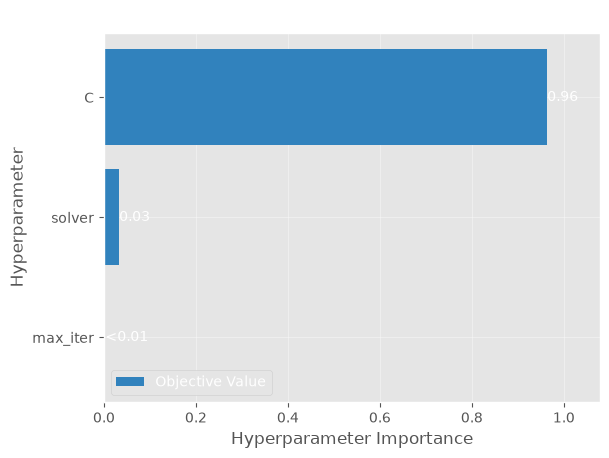

In [54]:
from optuna.visualization.matplotlib import plot_param_importances

plot_param_importances(
    study,
    evaluator=evaluator
)
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что вы видите и как вы прокомментируете, какие параметры важнее всего?

**Ответ:** В пределах проверенного диапазона сильнее всего на Gini влиял `C`. Влияние `solver` было заметно меньше. Слабое влияние `max_iter` может объясняться тем, что для многих конфигураций этого лимита уже хватало.

</div>

#### **Задание 3.3. Заключение** (0.25 балла)

Фуух, много конечно, ну да так уж вышло, что теперь делать, данные это всегда геморрой. Напоследок:

1. Зафиксируйте оптимальный набор гиперпараметров. 
2. Сохраните либо модель, либо pipeline для будущего себя в части advanced. 
3. Сделайте тестовый submission на [Kaggle](https://www.kaggle.com/t/6fd940fbeb1746a78031e5d0277f6105), если ещё не.

In [57]:
best_params = study.best_params
best_pipeline = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('column_transformer', column_transformer),
    ('model', LogisticRegression(**best_params))
])

best_pipeline.fit(X_main_train, y_main_train)

import joblib
joblib.dump(best_pipeline, 'best_pipeline.joblib')

test_probabilities = best_pipeline.predict_proba(matches_test)[:, 1]


submission = pd.DataFrame({
    'ID': matches_test['match_id'],
    'VALUE': test_probabilities
})
submission.to_csv('submission.csv', index=False)

submission.shape

(59748, 2)

In [58]:
joblib.dump(X_main_train, 'X_main_train.joblib')
joblib.dump(y_main_train, 'y_main_train.joblib')

joblib.dump(matches_train, 'matches_train.joblib')

['matches_train.joblib']